# Unidad 4 · Lectura de dígitos manuscritos

**Pregunta experimental.** ¿Qué efecto tiene el dropout en una CNN que lee casillas de un solo dígito? Se fija la partición, la inicialización, el optimizador y el presupuesto de épocas. Ejecución local en Windows: `taller.cmd entrenar`.

In [1]:
from pathlib import Path
import os
import sys

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "modelo.py").is_file())
os.chdir(raiz)
sys.path.insert(0, str(raiz))
os.environ["KERAS_BACKEND"] = "jax"
os.environ.setdefault("JAX_PLATFORMS", "cpu")

Out[1]: 'cpu'


## Datos y particiones

Se conservan los índices originales de `load_digits`. Se estratifica por clase. La prueba se reserva hasta haber elegido la configuración. Esta partición mide generalización a otras imágenes del mismo corpus.

In [2]:
import json
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as Imagen
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import cv2
from src.modelo import PESOS, cargar_modelo, imagen_dataset, preparar, predecir

SEMILLA = 41
datos = load_digits()
y = datos.target
X = np.stack([preparar(imagen_dataset(im)) for im in datos.images])
desarrollo, prueba = train_test_split(np.arange(len(y)), test_size=0.15, random_state=SEMILLA, stratify=y)
entreno, validacion = train_test_split(desarrollo, test_size=0.15 / 0.85, random_state=SEMILLA, stratify=y[desarrollo])
assert len(set(entreno) | set(validacion) | set(prueba)) == len(y)
print("Entrenamiento, validación y prueba:", len(entreno), len(validacion), len(prueba))
print("Forma de cada entrada:", X.shape[1:], "| Clases:", np.unique(y))


Entrenamiento, validación y prueba: 1257 270 270
Forma de cada entrada: (8, 8, 1) | Clases: [0 1 2 3 4 5 6 7 8 9]


## Dos configuraciones

Cada CNN aplica dos convoluciones y conserva información espacial antes de la capa densa. Se compara dropout apagado y activo. Se guardan los pesos de la época con menor pérdida de validación de cada configuración.

In [3]:
from keras import layers

EPOCAS, LOTE, TASA = 32, 32, 0.002
variantes = {"Base": 0.0, "Dropout": 0.35}
modelos, historiales, resumen = {}, {}, []

def construir(tasa_dropout):
    red = keras.Sequential([
        layers.Input((8, 8, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Flatten(), layers.Dense(48, activation="relu"),
        layers.Dropout(tasa_dropout), layers.Dense(10, activation="softmax"),
    ])
    red.compile(optimizer=keras.optimizers.Adam(TASA), loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return red

print(f"Semilla {SEMILLA}, épocas {EPOCAS}, lote {LOTE}, Adam {TASA}. Dropout: {variantes}")
for nombre, tasa in variantes.items():
    keras.utils.set_random_seed(SEMILLA)
    red = construir(tasa)
    restaurar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=EPOCAS,
                                              restore_best_weights=True)
    h = red.fit(X[entreno], y[entreno], validation_data=(X[validacion], y[validacion]),
                epochs=EPOCAS, batch_size=LOTE, callbacks=[restaurar], verbose=0).history
    mejor = int(np.argmin(h["val_loss"]))
    resumen.append({"variante": nombre, "época": mejor + 1, "loss_train": h["loss"][mejor],
                    "loss_val": h["val_loss"][mejor], "acc_train": h["accuracy"][mejor],
                    "acc_val": h["val_accuracy"][mejor]})
    modelos[nombre], historiales[nombre] = red, h
display(pd.DataFrame(resumen))


Semilla 41, épocas 32, lote 32, Adam 0.002. Dropout: {'Base': 0.0, 'Dropout': 0.35}


,variante,época,loss_train,loss_val,acc_train,acc_val
0,Base,24,0.003258,0.069753,1.000000,0.974074
1,Dropout,29,0.046853,0.045646,0.984885,0.985185


## Curvas por época y selección con validación

Configuración exportada: Dropout | Archivo: lector.keras


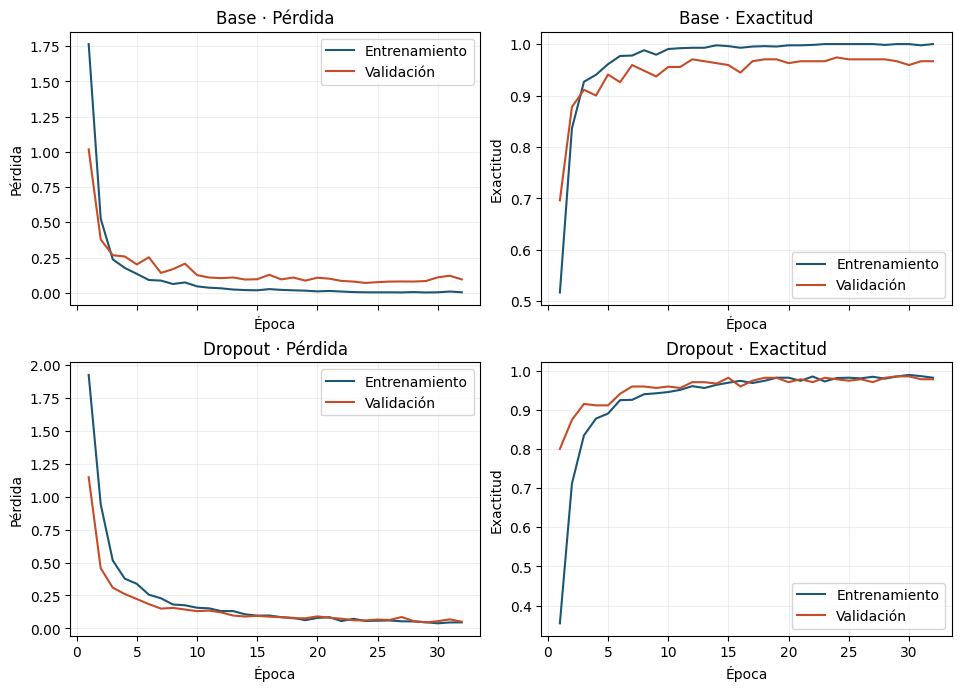

In [4]:
fig, ejes = plt.subplots(2, 2, figsize=(9.5, 6.8), sharex=True, layout="constrained")
for fila, (nombre, h) in enumerate(historiales.items()):
    epocas = np.arange(1, len(h["loss"]) + 1)
    for ax, clave, titulo in zip(ejes[fila], ["loss", "accuracy"], ["Pérdida", "Exactitud"]):
        ax.plot(epocas, h[clave], label="Entrenamiento", color="#1c5673")
        ax.plot(epocas, h["val_" + clave], label="Validación", color="#c54c27")
        ax.set(title=f"{nombre} · {titulo}", xlabel="Época", ylabel=titulo)
        ax.grid(alpha=0.2)
        ax.legend()
fig.savefig("assets/curvas.png", dpi=150)
plt.show()

ganador = min(resumen, key=lambda fila: fila["loss_val"])["variante"]
modelos[ganador].save(PESOS)
cargar_modelo.cache_clear()
print("Configuración exportada:", ganador, "| Archivo:", PESOS.name)


## Prueba independiente y reproducción de un fallo

Se selecciona el error de menor confianza del conjunto de prueba. Si todo se acierta, se muestra la lectura de menor confianza. El PNG conserva los píxeles que recibe la aplicación.

Prueba: 268/270 aciertos; exactitud = 0.9926.
{
  "dataset": "sklearn.load_digits",
  "indice": 1149,
  "etiqueta_real": 8,
  "digito": 2,
  "confianza_pct": 57.95,
  "variante": "Dropout"
}


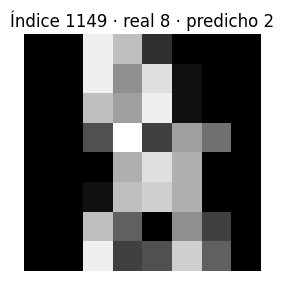

In [5]:
probabilidades = np.asarray(cargar_modelo()(X[prueba], training=False))
clases = probabilidades.argmax(axis=1)
aciertos = clases == y[prueba]
confianzas = probabilidades.max(axis=1)
errores = np.flatnonzero(~aciertos)
pos = int(errores[np.argmin(confianzas[errores])]) if len(errores) else int(confianzas.argmin())
indice = int(prueba[pos])
print(f"Prueba: {aciertos.sum()}/{len(prueba)} aciertos; exactitud = {aciertos.mean():.4f}.")
original = imagen_dataset(datos.images[indice])
assert cv2.imwrite("assets/caso_prueba.png", original)
salida = predecir(original)
assert salida["digito"] == int(clases[pos])
caso = {"dataset": "sklearn.load_digits", "indice": indice, "etiqueta_real": int(y[indice]),
        **salida, "variante": ganador}
Path("assets/caso_prueba.json").write_text(json.dumps(caso, indent=2), encoding="utf-8")
print(json.dumps(caso, indent=2, ensure_ascii=False))
fig, ax = plt.subplots(figsize=(2.7, 2.7), layout="constrained")
ax.imshow(original, cmap="gray", interpolation="nearest", vmin=0, vmax=255)
ax.set_title(f"Índice {indice} · real {y[indice]} · predicho {clases[pos]}")
ax.axis("off")
plt.show()

## Auditoría local de los pesos entrenados

La auditoría repite la inferencia sobre el modelo recién exportado. Registra las particiones, todos los errores y el efecto de la interpolación en la imagen de prueba. El hash identifica los pesos utilizados.

In [6]:
from pathlib import Path
import os
import sys
raiz_auditoria = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/modelo.py").is_file())
os.chdir(raiz_auditoria)
sys.path.insert(0, str(raiz_auditoria))
os.environ["KERAS_BACKEND"] = "jax"
from src.auditoria import auditar
auditoria = auditar()


{
  "alcance": "Auditoría de inferencia sobre los pesos exportados por U4.",
  "python": "3.12.14",
  "versiones": {
    "keras": "3.12.0",
    "jax": "0.6.2",
    "numpy": "2.2.6",
    "scikit-learn": "1.7.2",
    "pillow": "13.0.0"
  },
  "sha256_modelo": "30cd4955abb2bbcbbe8be095cd9bc7f89671ed02cc6e42eb61259d7ff52e2ea0",
  "particiones": {
    "entrenamiento": 1257,
    "validacion": 270,
    "prueba": 270
  },
  "particiones_disjuntas": true,
  "aciertos": 268,
  "total": 270,
  "exactitud": 0.9925925925925926,
  "errores": [
    {
      "indice": 1149,
      "real": 8,
      "predicho": 2,
      "confianza_pct": 57.95
    },
    {
      "indice": 1662,
      "real": 9,
      "predicho": 5,
      "confianza_pct": 89.55
    }
  ],
  "lecturas_bajo_90": 11,
  "errores_bajo_90": 2,
  "aciertos_bajo_90": 9,
  "interpolacion_caso": [
    {
      "interpolacion": "original",
      "tamano": 8,
      "digito": 2,
      "confianza_pct": 57.95
    },
    {
      "interpolacion": "vecino_mas